# Неделя 11 — Эксперименты и анализ ошибок

Цель: исследовать LR, объём train и минимум 10 ошибок. При отсутствии bert_metrics здесь видны только выполненные baseline-опыты; это не завершённое BERT-исследование.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'nlp_project').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
from nlp_project.core import corpus, clean, tokens, metrics, SEED
df = corpus()
train, val, test = [df[df.split == s].copy() for s in ('train', 'validation', 'test')]


,model,split,accuracy,precision_macro,recall_macro,f1_macro,n
0,bow_nb,validation,0.801020,0.802564,0.801020,0.800766,196
1,bow_nb,test,0.802030,0.802778,0.802154,0.801949,197
2,tfidf_lr,validation,0.760204,0.760231,0.760204,0.760198,196
3,tfidf_lr,test,0.796954,0.797459,0.796846,0.796823,197
4,tfidf_nb,validation,0.790816,0.791089,0.790816,0.790767,196
5,tfidf_nb,test,0.807107,0.809092,0.807308,0.806863,197
6,word2vec_lr,validation,0.673469,0.676110,0.673469,0.672241,196
7,word2vec_lr,test,0.695431,0.695424,0.695424,0.695424,197
8,fasttext_lr,validation,0.622449,0.623270,0.622449,0.621819,196
9,fasttext_lr,test,0.634518,0.637964,0.634096,0.631776,197


BERT-эксперименты пока не выполнены: сетевой блокер. Результаты не выдумываются.


,id,text,label,prediction,reason,analysis,proposed_fix
0,amazon-0003,Tied to charger for conversations lasting more...,0,1,Косвенная жалоба,Зависимость от зарядки выражена без типичных о...,Добавить примеры жалоб на автономность.
1,amazon-0080,I wear it everyday and it holds up very well.,1,0,Устойчивое выражение,holds up very well описывает долговечность; ра...,Больше примеров устойчивых оборотов.
2,amazon-0119,)Setup couldn't have been simpler.,1,0,Контекст отрицания,could not have been simpler — позитивная конст...,Контекстная модель и примеры сложных отрицаний.
3,amazon-0244,It defeats the purpose of a bluetooth headset.,0,1,Неявная оценка,defeats the purpose выражает отрицательную оце...,Доменные фразы и контекстные embeddings.
4,amazon-0313,Phone now holds charge like it did when it was...,1,0,Сравнение,Восстановление прежней ёмкости батареи — полож...,Примеры сравнений состояния товара.
5,amazon-0324,I have 2-3 bars on my cell phone when I am hom...,0,1,Опечатка и отрицание,cant not hear — шумная разговорная конструкция...,Контролируемая нормализация опечаток без потер...
6,amazon-0333,"It fits comfortably in either ear, the sound i...",1,0,Несколько аспектов,"Положительные оценки удобства, звука и заряда ...",Аспектный анализ; расширение корпуса.
7,amazon-0338,"It was an inexpensive piece, but I would still...",0,1,Ожидание и уступка,"Низкая цена положительна, но ожидалось лучшее ...",Примеры смешанных оценок и конструкций с but.
8,amazon-0341,Was not happy.,0,1,Короткое отрицание,not happy не распознано надёжно при ограниченн...,Контекстные отрицания; больше коротких отзывов.
9,amazon-0350,Were JERKS on the phone.,0,1,Редкая лексика,"JERKS выражает негатив, но слово редко в обуча...",Расширить лексику и использовать предобученные...


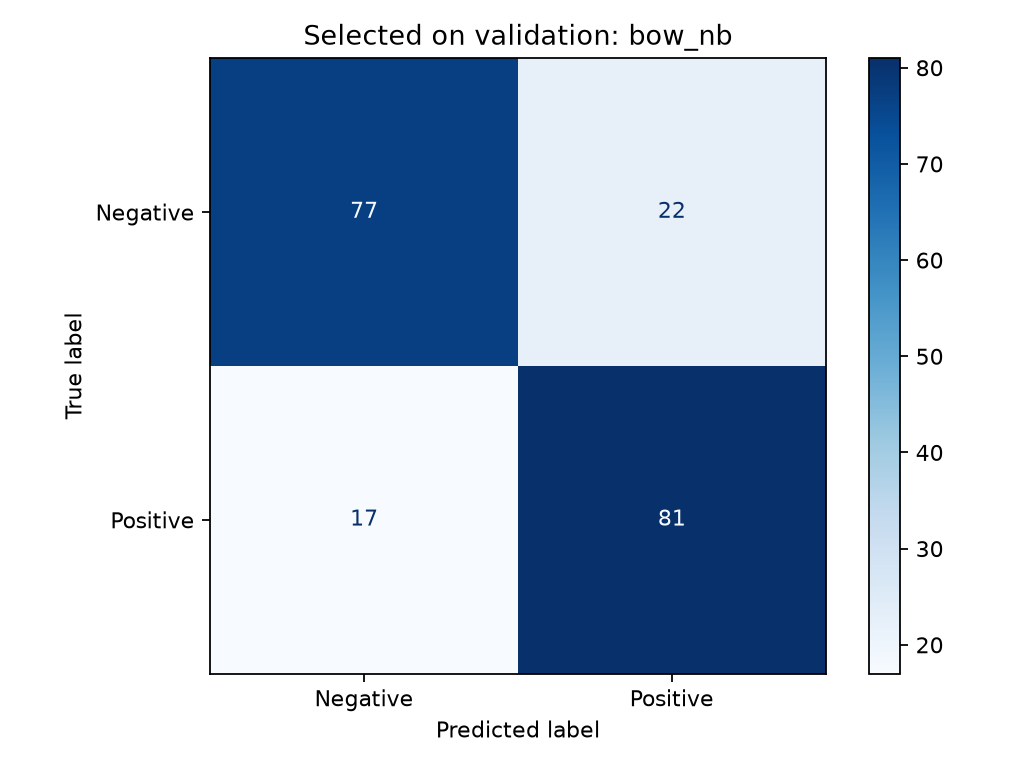

In [2]:
scores = pd.read_csv(ROOT / 'reports/all_metrics.csv')
display(scores)
if (ROOT / 'reports/bert_training_history.csv').exists():
    history = pd.read_csv(ROOT / 'reports/bert_training_history.csv')
    display(history.groupby(['model','lr','fraction']).f1_macro.max().to_frame('best_validation_f1'))
    display(Image(filename=str(ROOT / 'reports/figures/bert_learning_curves.png')))
else:
    print('BERT-эксперименты пока не выполнены: сетевой блокер. Результаты не выдумываются.')
errors = pd.read_csv(ROOT / 'reports/error_analysis.csv')
display(errors[['id','text','label','prediction','reason','analysis','proposed_fix']])
assert len(errors) >= 10
display(Image(filename=str(ROOT / 'reports/figures/confusion_matrix.png')))


## Выводы

Ошибки: сложное отрицание, косвенная жалоба, редкая лексика, смешанные аспекты. Это гипотезы для будущей работы, не доказанные причины. Нельзя улучшать модель по этим test-ошибкам и снова выдавать оценку на том же test за независимую.